# Version 1 

Use only train.csv and test.csv data, fit a linear regression model to it. This prediction can serve as our baseline.

# Preprocessing for Ridge Regression
Requires pandas and scikit-learn >= 1.3 (`TargetEncoder`).

1. Drop constant FURNISHED and FEE columns
2. Extract approval year/month
3. One-hot encode town, flat type and flat model
4. Target encode the combined town/street/block identifier
5. Standardize numeric, date and block-encoded features.
6. Keep one-hot indicators as 0/1 and MONTHLY_RENT in its original units.

See [scikit-learn TargetEncoder documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.TargetEncoder.html).

In [1]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder

TARGET = "MONTHLY_RENT"
NUMERIC_FEATURES = ["FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE"]
DATE_FEATURES = ["RENT_APPROVAL_DATE"]
ONEHOT_FEATURES = ["TOWN", "FLAT_TYPE", "FLAT_MODEL"]
BLOCK_FEATURES = ["TOWN", "STREET", "BLOCK"]


def split_xy(data):
    """Separate the optional target and remove constant columns without mutating data."""
    X = data.drop(columns=[TARGET, "FURNISHED", "FEE"], errors="ignore").copy()
    y = data[TARGET].copy() if TARGET in data.columns else None
    return X, y


def extract_date_features(X):
    result = pd.DataFrame(index=X.index)
    for col in X.columns:
        dates = pd.to_datetime(X[col], format="%Y-%m", errors="coerce")
        result[f"{col}_year"] = dates.dt.year
        result[f"{col}_month"] = dates.dt.month
    return result


def clean_categories(X):
    result = X.copy()
    for col in result.columns:
        values = result[col].astype("string").str.strip().str.upper()
        values = values.str.replace(r"\s+", " ", regex=True)
        if col == "FLAT_TYPE":
            values = values.str.replace(r"^(\d+)\s*[- ]\s*ROOM$", r"\1-ROOM", regex=True)
        result[col] = values.fillna("<MISSING>").replace("", "<MISSING>").astype(object)
    return result


def extract_block_id(X):
    parts = clean_categories(X[BLOCK_FEATURES])
    return pd.DataFrame(
        {"BLOCK_ID": parts["TOWN"] + "|" + parts["STREET"] + "|" + parts["BLOCK"]},
        index=X.index,
    )


def date_feature_names(transformer, input_features):
    return [f"{col}_{part}" for col in input_features for part in ("year", "month")]


def block_feature_names(transformer, input_features):
    return ["BLOCK_ID"]


def make_preprocessor():
    """Return a fresh preprocessor; fit only on the training partition."""
    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scale", StandardScaler()),
    ])
    date_pipeline = Pipeline([
        ("extract", FunctionTransformer(extract_date_features, validate=False,
                                        feature_names_out=date_feature_names)),
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scale", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("clean", FunctionTransformer(clean_categories, validate=False,
                                      feature_names_out="one-to-one")),
        # Keep all categories for Ridge; unseen categories become all-zero indicators.
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    block_pipeline = Pipeline([
        ("extract", FunctionTransformer(extract_block_id, validate=False,
                                        feature_names_out=block_feature_names)),
        ("encode", TargetEncoder(target_type="continuous", smooth="auto",
                                 cv=5, shuffle=True, random_state=42)),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("dates", date_pipeline, DATE_FEATURES),
        ("categorical", categorical_pipeline, ONEHOT_FEATURES),
        ("block", block_pipeline, BLOCK_FEATURES),
    ], remainder="drop", sparse_threshold=0)


def preprocess(data, *, preprocessor=None):
    """Return (encoded X, optional y, fitted preprocessor).

    Omit preprocessor to fit on labeled training data (at least 5 rows).
    Pass the returned preprocessor to transform validation or test data.
    """
    X, y = split_xy(data)
    if preprocessor is None:
        if y is None:
            raise ValueError("Training data must contain MONTHLY_RENT.")
        if y.isna().any():
            raise ValueError("Training targets must not contain missing values.")
        if len(X) < 5:
            raise ValueError("TargetEncoder with cv=5 requires at least 5 training rows.")
        preprocessor = make_preprocessor()
        encoded = preprocessor.fit_transform(X, y)
    else:
        encoded = preprocessor.transform(X)
    encoded = pd.DataFrame(encoded, columns=preprocessor.get_feature_names_out(), index=X.index)
    return encoded, y, preprocessor

In [2]:
# Preserve alphanumeric blocks and their textual identity in both files.
train = pd.read_csv("train.csv", dtype={"BLOCK": "string"})
test = pd.read_csv("test.csv", dtype={"BLOCK": "string"})

X_train, y_train, preprocessor = preprocess(train)
X_test, y_test, _ = preprocess(test, preprocessor=preprocessor)
print("Training:", X_train.shape, "Test:", X_test.shape)
X_train.head()

/Users/apple/Documents/modules/CS5242/cs5242/lib/python3.14/site-packages/sklearn/preprocessing/_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Training: (150000, 57) Test: (50000, 57)


,numeric__FLOOR_AREA_SQM,numeric__LEASE_COMMENCE_DATE,dates__RENT_APPROVAL_DATE_year,dates__RENT_APPROVAL_DATE_month,categorical__TOWN_ANG MO KIO,categorical__TOWN_BEDOK,categorical__TOWN_BISHAN,categorical__TOWN_BUKIT BATOK,categorical__TOWN_BUKIT MERAH,categorical__TOWN_BUKIT PANJANG,...,categorical__FLAT_MODEL_NEW GENERATION,categorical__FLAT_MODEL_PREMIUM APARTMENT,categorical__FLAT_MODEL_PREMIUM APARTMENT LOFT,categorical__FLAT_MODEL_PREMIUM MAISONETTE,categorical__FLAT_MODEL_SIMPLIFIED,categorical__FLAT_MODEL_STANDARD,categorical__FLAT_MODEL_TERRACE,categorical__FLAT_MODEL_TYPE S1,categorical__FLAT_MODEL_TYPE S2,block__BLOCK_ID
0,-0.013961,1.668515,-1.309188,-1.470916,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007585
1,0.686444,0.798365,-1.309188,-1.470916,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.451720
2,-1.167568,-1.179249,-1.309188,-1.470916,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.124511
3,0.109640,1.510306,-1.309188,-1.470916,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.233924
4,0.356842,0.798365,-1.309188,-1.470916,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.380304


In [3]:
model = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("regressor", Ridge(alpha=1.0)),
])

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Split raw data before fitting preprocessing.
# latest month - 2 months for val, rest for train
approval_dates = pd.to_datetime(train["RENT_APPROVAL_DATE"])
cutoff = approval_dates.max().to_period("M").start_time - pd.DateOffset(months=2)

is_validation = approval_dates >= cutoff
training_data = train.loc[~is_validation]
validation_data = train.loc[is_validation]

X_fit, y_fit = split_xy(training_data)
X_val, y_val = split_xy(validation_data)

# Fits preprocessing and Ridge using only the training partition.
model.fit(X_fit, y_fit)
val_predictions = model.predict(X_val)

print(f"Training rows:   {len(X_fit):,}")
print(f"Validation rows: {len(X_val):,}")
print(f"MAE:  {mean_absolute_error(y_val, val_predictions):,.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val, val_predictions)):,.2f}")
print(f"R²:   {r2_score(y_val, val_predictions):.3f}")


Training rows:   141,076
Validation rows: 8,924
MAE:  414.74
RMSE: 570.36
R²:   0.224


/Users/apple/Documents/modules/CS5242/cs5242/lib/python3.14/site-packages/sklearn/preprocessing/_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


In [5]:
X_all, y_all = split_xy(train)
X_test_raw, _ = split_xy(test)

model.fit(X_all, y_all)
test_predictions = model.predict(X_test_raw)

submission = pd.DataFrame({
    "Id": range(len(test_predictions)),
    "Predicted": test_predictions,
})
submission.to_csv("predictions/ridge_regression_submission.csv", index=False)

/Users/apple/Documents/modules/CS5242/cs5242/lib/python3.14/site-packages/sklearn/preprocessing/_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


# CatBoost regression
Run the earlier imports/helper definitions and data-loading cells first. If CatBoost is missing, run `%pip install catboost` in a notebook cell and restart the kernel if requested.

This section uses cleaned raw categories, without the Ridge encoder/scaler. It validates on the last 12 months, reports RMSE alongside a freshly fitted Ridge on the same split, then refits CatBoost on all labeled rows and writes `submission_catboost.csv`.

Early stopping chooses the tree count using validation RMSE, so this is a model-selection score, not an untouched final evaluation. Compare additional chronological periods before extensive tuning. Date features do not guarantee extrapolation to future market trends.

Reference: [CatBoost training API](https://catboost.ai/docs/en/concepts/python-reference_catboostregressor_fit).

In [9]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error

CATBOOST_CATEGORICAL = ["TOWN", "STREET", "FLAT_TYPE", "FLAT_MODEL", "BLOCK_ID"]


def make_catboost_features(data):
    """Build target-independent features while preserving input row order."""

    # clean categorical features - all capital, remove extra spaces, and replace missing values with "<MISSING>"
    # extract block ID from TOWN, STREET, BLOCK columns and add as a new categorical feature
    X = clean_categories(data[["TOWN", "STREET", "FLAT_TYPE", "FLAT_MODEL"]])
    X["BLOCK_ID"] = extract_block_id(data)["BLOCK_ID"]

    dates = pd.to_datetime(data["RENT_APPROVAL_DATE"], format="%Y-%m", errors="raise")
    for col in ["FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE"]:
        X[col] = pd.to_numeric(data[col], errors="coerce").astype(float)

    # split the RENT_APPROVAL_DATE into year and month
    # and create a month index relative to Jan 2021
    X["APPROVAL_YEAR"] = dates.dt.year
    X["APPROVAL_MONTH"] = dates.dt.month
    X["MONTH_INDEX"] = (dates.dt.year - 2021) * 12 + dates.dt.month - 1
    X["BUILDING_AGE"] = dates.dt.year - X["LEASE_COMMENCE_DATE"]
    # CatBoost accepts numeric NaN values, but categorical values must be strings.
    return X


X_cb = make_catboost_features(train)
y_cb = pd.to_numeric(train[TARGET], errors="raise")
X_cb_test = make_catboost_features(test)

# last 12 months for validation, rest for training
cb_dates = pd.to_datetime(train["RENT_APPROVAL_DATE"], format="%Y-%m", errors="raise")
VALIDATION_MONTHS = 12
cb_cutoff = cb_dates.max().to_period("M").start_time - pd.DateOffset(months=VALIDATION_MONTHS - 1)
cb_fit_mask = cb_dates < cb_cutoff
cb_val_mask = cb_dates >= cb_cutoff

print(f"Train: {cb_dates[cb_fit_mask].min():%Y-%m} to {cb_dates[cb_fit_mask].max():%Y-%m} ({cb_fit_mask.sum():,} rows)")
print(f"Validation: {cb_dates[cb_val_mask].min():%Y-%m} to {cb_dates[cb_val_mask].max():%Y-%m} ({cb_val_mask.sum():,} rows)")

Train: 2021-01 to 2024-03 (114,842 rows)
Validation: 2024-04 to 2025-03 (35,158 rows)


In [10]:
CB_PARAMS = dict(
    loss_function="RMSE",
    eval_metric="RMSE",
    depth=6,
    learning_rate=0.05,
    l2_leaf_reg=5,
    random_seed=42,
    thread_count=4,
    allow_writing_files=False,
)
catboost_validation_model = CatBoostRegressor(iterations=2000, **CB_PARAMS)
catboost_validation_model.fit(
    X_cb.loc[cb_fit_mask], y_cb.loc[cb_fit_mask],
    cat_features=CATBOOST_CATEGORICAL,
    eval_set=(X_cb.loc[cb_val_mask], y_cb.loc[cb_val_mask]),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=200,
)
cb_val_predictions = catboost_validation_model.predict(X_cb.loc[cb_val_mask])
cb_best_iterations = catboost_validation_model.tree_count_
print(f"Selected number of trees: {cb_best_iterations}")

# Refit Ridge on this exact split; the earlier model was fitted on all rows.
ridge_comparison = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("regressor", Ridge(alpha=1.0)),
])
X_cb_raw, _ = split_xy(train)
ridge_comparison.fit(X_cb_raw.loc[cb_fit_mask], y_cb.loc[cb_fit_mask])
ridge_val_predictions = ridge_comparison.predict(X_cb_raw.loc[cb_val_mask])

# The training mean is the constant baseline appropriate for squared error.
mean_val_predictions = np.full(cb_val_mask.sum(), y_cb.loc[cb_fit_mask].mean())
cb_validation_scores = pd.DataFrame([
    {"Model": name, "RMSE": np.sqrt(mean_squared_error(y_cb.loc[cb_val_mask], prediction))}
    for name, prediction in [
        ("Training mean", mean_val_predictions),
        ("Ridge", ridge_val_predictions),
        ("CatBoost", cb_val_predictions),
    ]
]).sort_values("RMSE")
print(cb_validation_scores.to_string(index=False))

0:	learn: 714.2795962	test: 824.4722534	best: 824.4722534 (0)	total: 77ms	remaining: 2m 33s
200:	learn: 484.5144758	test: 483.3059601	best: 483.3059601 (200)	total: 2.92s	remaining: 26.2s
400:	learn: 480.7249220	test: 478.9570148	best: 478.9570148 (400)	total: 6.04s	remaining: 24.1s
600:	learn: 478.1078115	test: 477.0512724	best: 477.0512724 (600)	total: 9.08s	remaining: 21.1s
800:	learn: 476.1432574	test: 475.8998097	best: 475.8998097 (800)	total: 12.2s	remaining: 18.3s
1000:	learn: 474.4839384	test: 475.3565500	best: 475.3565500 (1000)	total: 15.4s	remaining: 15.4s
1200:	learn: 473.0172914	test: 475.0781484	best: 475.0669305 (1180)	total: 18.6s	remaining: 12.3s
1400:	learn: 471.6210365	test: 474.7080901	best: 474.6701488 (1389)	total: 21.8s	remaining: 9.34s
1600:	learn: 470.3260122	test: 474.4695099	best: 474.4547909 (1567)	total: 25.2s	remaining: 6.27s
1800:	learn: 469.1352004	test: 474.3766431	best: 474.3204359 (1714)	total: 28.7s	remaining: 3.17s
Stopped by overfitting detector  (

/Users/apple/Documents/modules/CS5242/cs5242/lib/python3.14/site-packages/sklearn/preprocessing/_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


        Model       RMSE
     CatBoost 474.320436
        Ridge 622.556412
Training mean 846.754876


In [11]:
# Refit using all labels and the tree count selected during validation.
catboost_final_model = CatBoostRegressor(iterations=cb_best_iterations, **CB_PARAMS)
catboost_final_model.fit(X_cb, y_cb, cat_features=CATBOOST_CATEGORICAL, verbose=200)
catboost_test_predictions = catboost_final_model.predict(X_cb_test)
if not np.isfinite(catboost_test_predictions).all():
    raise ValueError("Predictions must all be finite before exporting.")
catboost_submission = pd.DataFrame({
    "Id": np.arange(len(test)),
    "Predicted": catboost_test_predictions,
})
catboost_submission.to_csv("predictions/catboost_submission.csv", index=False)
print(f"Saved catboost_submission.csv ({len(catboost_submission):,} rows)")
catboost_submission.head()

0:	learn: 730.8476501	total: 27.1ms	remaining: 46.4s
200:	learn: 483.5937471	total: 3.79s	remaining: 28.5s
400:	learn: 479.7748310	total: 7.76s	remaining: 25.4s
600:	learn: 477.3151247	total: 11.7s	remaining: 21.7s
800:	learn: 475.5875746	total: 15.8s	remaining: 18s
1000:	learn: 474.1652914	total: 19.9s	remaining: 14.2s
1200:	learn: 472.8170614	total: 24.1s	remaining: 10.3s
1400:	learn: 471.5737653	total: 28.5s	remaining: 6.38s
1600:	learn: 470.3768519	total: 33s	remaining: 2.35s
1714:	learn: 469.7412767	total: 35.5s	remaining: 0us
Saved catboost_submission.csv (50,000 rows)


,Id,Predicted
0,0,2836.955755
1,1,3745.180975
2,2,3245.048786
3,3,3109.109120
4,4,3282.353039


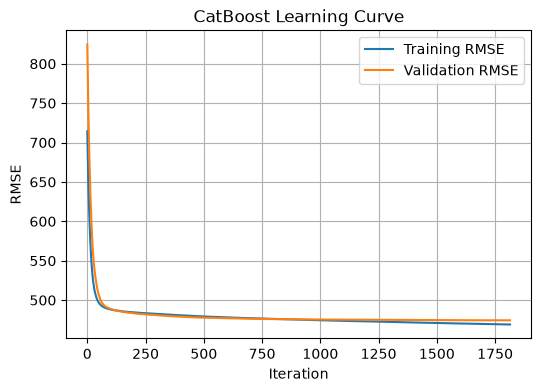

In [17]:
import matplotlib.pyplot as plt

results = catboost_validation_model.get_evals_result()

plt.figure(figsize=(6, 4))
plt.plot(results["learn"]["RMSE"], label="Training RMSE")
plt.plot(results["validation"]["RMSE"], label="Validation RMSE")
plt.xlabel("Iteration")
plt.ylabel("RMSE")
plt.title("CatBoost Learning Curve")
plt.legend()
plt.grid()
plt.show()